# 09 · 有限观察范围的局部突出度二次确认

保留旧595个触发、旧边界和11号复核窗口，只新增“支持／不支持／不确定”的形态对照。没有自动剔除候选、删除epoch、修改PTP或训练模型。

新指标使用SciPy `peak_prominences`，不是峰减前窗均值，也不是峰离零点的距离。官方文档说明可用wlen限制局部搜索；有限窗口会改变突出度含义，本轮有意测量局部量：[SciPy官方说明](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.peak_prominences.html)。实际运行SciPy版本记录在run_record.json，未因网页版本升级软件。

本轮门槛为预先固定的小网格8/12/18µV，**不照搬旧绝对幅值25µV，不自动选择最好的一档**。所有结果是训练开发集、用户挑选标注上的探索，不是独立验证性能。


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'configs/bounded_prominence_secondary.json').exists())
OUT=ROOT/'outputs/bounded_prominence_secondary_v1'
f=pd.read_csv(OUT/'candidate_features.csv')
s=pd.read_csv(OUT/'candidate_secondary_status.csv')
n=pd.read_csv(OUT/'marked_negative_comparison.csv')
p=pd.read_csv(OUT/'legacy_positive_example_comparison.csv')
config=json.loads((OUT/'config_snapshot.json').read_text())
record=json.loads((OUT/'run_record.json').read_text())
display(pd.Series(record).drop('config').to_frame('run record'))


,run record
parent_candidates,595
detector_parameters_unchanged,True
source_config_sha256,eccd8412f204e3270627898baa729d2a9154051f32e503...
old_boundaries_unchanged,True
notebook11_unchanged,True
actual_suppression,False
best_threshold_selected,False
thresholds_inherit_old_25uv,False
positive_examples,203
negative_marked_candidates,23


## 1. 三项检查分别做什么？

1. 在旧主波峰附近±0.06秒内找实际局部极值，正负极性都可；选离锚点最近的极值，不挑最有利的大峰。
2. 每个峰的突出度限于左右各0.35秒，峰两侧基底共同定义等高线。单纯下降到另一个水平、不形成独立局部峰，不足以支持新眨眼。
3. 在两侧0.08–0.35秒内寻找最近的0.12秒局部背景。允许轻微起伏，但q90−q10≤15µV、斜率绝对值≤40µV/秒；背景覆盖已知的另一个主波时保留不确定。

至少两个额区通道也需支持对应门槛。背景可靠性不足、观察未完成、NaN/Inf或近重复锚点均保留不确定，不将缺乏参考当作非眨眼证据。这里只使用到判定时刻已经可用的其他候选信息，未来才完成的候选不参与本次背景资格判断。


In [2]:
display(pd.Series(config,name='predeclared development settings').to_frame())

,predeclared development settings
version,bounded_prominence_secondary_v1
status,development comparison only; no final threshol...
domain,existing raw EEG causal notch60 + lowpass10Hz ...
frontal_channels,"[EEG_F3, EEG_Fz, EEG_F4]"
anchor_peak_search_radius_seconds,0.06
prominence_half_window_seconds,0.35
reference_search_outer_seconds,0.35
reference_search_inner_seconds,0.08
reference_window_seconds,0.12
reference_step_seconds,0.02


## 2. 全部候选分布

not_supported只表示此试验条件不支持独立主波，尚不是确认非眨眼。uncertain继续保留旧候选；不以恢复期长或找不到平台为理由硬删连续眨眼。


In [3]:
display(pd.read_csv(OUT/'all_candidate_summary.csv'))
display(f.groupby('feature_status').size().rename('candidates').to_frame())


,threshold_uv,secondary_status,candidates
0,8.0,not_supported,3
1,8.0,supported,328
2,8.0,uncertain,264
3,12.0,not_supported,6
4,12.0,supported,325
5,12.0,uncertain,264
6,18.0,not_supported,12
7,18.0,supported,319
8,18.0,uncertain,264


,candidates
feature_status,
evaluable,331
uncertain,264


## 3. 用户标出的平台／假阳性候选

两个文件共23个已标候选，其中19个非启动期。这里只衡量已选负例的再确认情况，不把未标出的候选视为真阳性，不能计算总体精确率或误报率。

非启动期19个负例：8/12/18µV三档分别有1/3/5个不受支持、7/5/3个仍受支持，另11个不确定。严格的有限突出度+背景资格结果与之前简单参考电平的“20/23不足25µV”不是同一规则，不能混用。


In [4]:
negative=n[~n.startup]
display(negative.groupby(['threshold_uv','secondary_status']).size().unstack(fill_value=0))
display(negative.loc[negative.threshold_uv.eq(12),['edf_name','blink_candidate_id','prominence_uv','support_channels','secondary_status','reason']])


secondary_status,not_supported,supported,uncertain
threshold_uv,,,
8.0,1,7,11
12.0,3,5,11
18.0,5,3,11


,edf_name,blink_candidate_id,prominence_uv,support_channels,secondary_status,reason
13,F_05_SE003_CBCol_Train04.edf,F_05_SE003_CBCol_Train04_B0010,36.294108,3,supported,bounded_prominence_and_frontal_support
16,F_05_SE003_CBCol_Train04.edf,F_05_SE003_CBCol_Train04_B0020,7.946890,1,not_supported,weak_bounded_prominence_in_reliable_context
19,F_05_SE003_CBCol_Train04.edf,F_05_SE003_CBCol_Train04_B0028,17.215497,2,uncertain,left_background_unreliable
22,F_05_SE003_CBCol_Train04.edf,F_05_SE003_CBCol_Train04_B0047,28.356603,2,supported,bounded_prominence_and_frontal_support
25,F_05_SE003_CBCol_Train04.edf,F_05_SE003_CBCol_Train04_B0054,19.971248,2,uncertain,left_background_unreliable
28,F_05_SE003_CBCol_Train04.edf,F_05_SE003_CBCol_Train04_B0082,22.692976,3,uncertain,left_background_unreliable;background_overlaps...
31,F_05_SE003_CBCol_Train04.edf,F_05_SE003_CBCol_Train04_B0089,11.174582,2,uncertain,left_background_unreliable
34,F_05_SE003_CBCol_Train04.edf,F_05_SE003_CBCol_Train04_B0090,29.013053,3,uncertain,left_background_unreliable;background_overlaps...
37,F_05_SE003_CBCol_Train04.edf,F_05_SE003_CBCol_Train04_B0109,25.539352,3,uncertain,left_background_unreliable;right_background_un...
40,F_05_SE003_CBCol_Train04.edf,F_05_SE003_CBCol_Train04_B0132,16.348853,2,uncertain,left_background_unreliable


## 4. 已有人工眨眼正例会不会被误删？

按同一旧检测父候选／人工区间关系比较，不通过重新匹配提高表面成绩。已有人工标注来自原始域，因此用于事件级保留对照，不当作新分支的精确边界真值。与新负例冲突的参考另列。

非启动期183个人工正例中，122个有受支持父候选、59个有不确定父候选而继续保留；2个原来就没有旧父候选重叠，不能算本次二次条件新增漏检。三档均未新增“所有父候选均不支持”的正例，但保守保留不确定也限制了排除误报的能力。


In [5]:
positive=p[~p.startup & ~p.positive_negative_review_conflict]
display(positive.groupby(['threshold_uv','positive_reference_status']).size().unstack(fill_value=0))
display(p[p.positive_negative_review_conflict][['edf_name','manual_id','threshold_uv','positive_reference_status','parent_ids']])


positive_reference_status,no_old_parent_overlap,supported,uncertain_retained
threshold_uv,,,
8.0,2,122,59
12.0,2,122,59
18.0,2,122,59


,edf_name,manual_id,threshold_uv,positive_reference_status,parent_ids
351,F_05_SE003_CBCol_Train04.edf,F_05_SE003_CBCol_Train04_M0002,8.0,uncertain_retained,F_05_SE003_CBCol_Train04_B0002
352,F_05_SE003_CBCol_Train04.edf,F_05_SE003_CBCol_Train04_M0002,12.0,uncertain_retained,F_05_SE003_CBCol_Train04_B0002
353,F_05_SE003_CBCol_Train04.edf,F_05_SE003_CBCol_Train04_M0002,18.0,uncertain_retained,F_05_SE003_CBCol_Train04_B0002
354,F_05_SE003_CBCol_Train04.edf,F_05_SE003_CBCol_Train04_M0003,8.0,uncertain_retained,F_05_SE003_CBCol_Train04_B0003
355,F_05_SE003_CBCol_Train04.edf,F_05_SE003_CBCol_Train04_M0003,12.0,uncertain_retained,F_05_SE003_CBCol_Train04_B0003
356,F_05_SE003_CBCol_Train04.edf,F_05_SE003_CBCol_Train04_M0003,18.0,uncertain_retained,F_05_SE003_CBCol_Train04_B0003
360,F_05_SE003_CBCol_Train04.edf,F_05_SE003_CBCol_Train04_M0005,8.0,uncertain_retained,F_05_SE003_CBCol_Train04_B0006
361,F_05_SE003_CBCol_Train04.edf,F_05_SE003_CBCol_Train04_M0005,12.0,uncertain_retained,F_05_SE003_CBCol_Train04_B0006
362,F_05_SE003_CBCol_Train04.edf,F_05_SE003_CBCol_Train04_M0005,18.0,uncertain_retained,F_05_SE003_CBCol_Train04_B0006


## 5. 相邻真实眨眼不能靠长禁检期硬合并

查看人工间隔≤0.5秒的相邻眨眼对。非启动且无正负标注冲突的11对，在三档条件下均保留两边的旧重叠候选，其中一些依靠uncertain保留。它不是证明所有连续眨眼都能检出，只说明本组没有因强求平台而新增硬删。


In [6]:
a=pd.read_csv(OUT/'adjacent_blink_pair_audit.csv')
good=a[~a.either_startup & ~a.either_review_conflict]
display(good.groupby('threshold_uv').agg(pairs=('both_retained','size'),both_retained=('both_retained','sum')))
display(good[good.threshold_uv.eq(12)])


,pairs,both_retained
threshold_uv,,
8.0,11,11
12.0,11,11
18.0,11,11


,edf_name,first_manual_id,second_manual_id,gap_seconds,threshold_uv,both_have_old_parent,both_retained,first_status,second_status,either_startup,either_review_conflict
2,F_05_SE001_CBCol_Train02.edf,F_05_SE001_CBCol_Train02_M0025,F_05_SE001_CBCol_Train02_M0026,0.478212,12.0,True,True,supported,supported,False,False
3,F_05_SE001_CBCol_Train02.edf,F_05_SE001_CBCol_Train02_M0042,F_05_SE001_CBCol_Train02_M0043,0.109306,12.0,True,True,uncertain_retained,uncertain_retained,False,False
7,F_05_SE002_CBCol_Train01.edf,F_05_SE002_CBCol_Train01_M0025,F_05_SE002_CBCol_Train01_M0026,0.420753,12.0,True,True,supported,supported,False,False
18,F_05_SE003_CBCol_Train04.edf,F_05_SE003_CBCol_Train04_M0013,F_05_SE003_CBCol_Train04_M0014,0.457717,12.0,True,True,supported,supported,False,False
19,F_05_SE003_CBCol_Train04.edf,F_05_SE003_CBCol_Train04_M0047,F_05_SE003_CBCol_Train04_M0048,0.321085,12.0,True,True,uncertain_retained,supported,False,False
20,F_05_SE003_CBCol_Train04.edf,F_05_SE003_CBCol_Train04_M0053,F_05_SE003_CBCol_Train04_M0054,0.266432,12.0,True,True,uncertain_retained,supported,False,False
21,F_05_SE003_CBCol_Train04.edf,F_05_SE003_CBCol_Train04_M0054,F_05_SE003_CBCol_Train04_M0055,0.280096,12.0,True,True,supported,supported,False,False
22,F_05_SE003_CBCol_Train04.edf,F_05_SE003_CBCol_Train04_M0055,F_05_SE003_CBCol_Train04_M0056,0.150295,12.0,True,True,supported,supported,False,False
23,F_05_SE003_CBCol_Train04.edf,F_05_SE003_CBCol_Train04_M0057,F_05_SE003_CBCol_Train04_M0058,0.389401,12.0,True,True,supported,supported,False,False
24,F_05_SE003_CBCol_Train04.edf,F_05_SE003_CBCol_Train04_M0059,F_05_SE003_CBCol_Train04_M0060,0.498707,12.0,True,True,supported,supported,False,False


## 6. 看实际等高线、两侧参考和正式信号

下面固定展示：一个不受支持的已标负例、此前讨论的F08 B0009残留误判，以及完整复核区间内的F05 B0008人工正例。12µV仅用于图上显示状态，不表示选定默认或最终门槛。

上图在新定位分支上标出实际峰、SciPy基底间等高线、左右参考；下图为正式分析信号。两者时序不能互换。**F08 B0009在当前规则下仍受支持**，是方法局限的例子，不隐藏它，也不为消除此个例直接调参数。


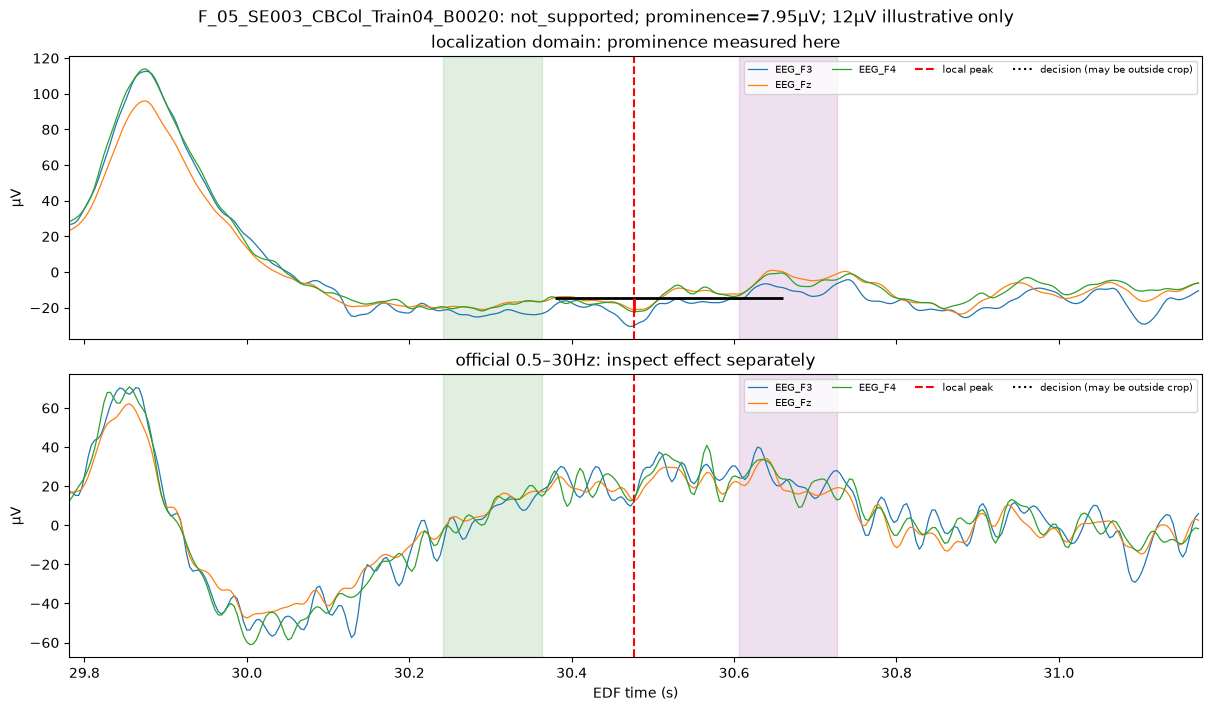

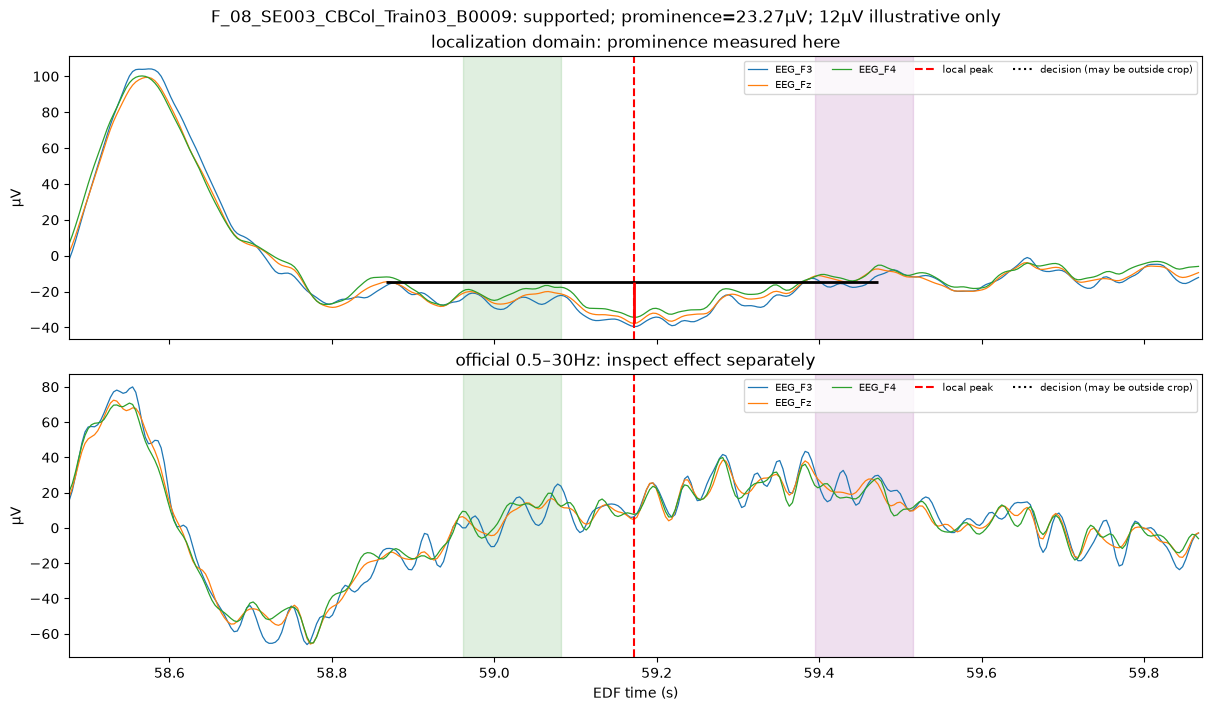

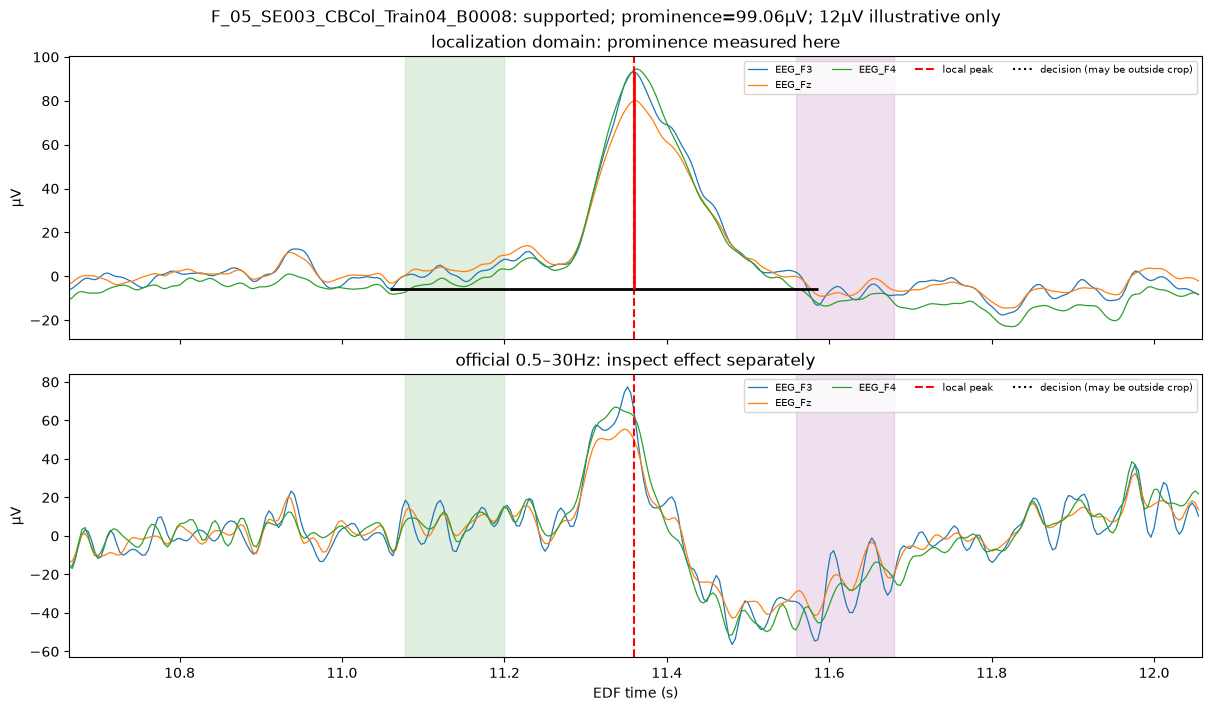

In [7]:
index=pd.read_csv(ROOT/'outputs/blink_candidate_review/file_index.csv').set_index('edf_name')
examples=[('F_05_SE003_CBCol_Train04.edf','B0020'),('F_08_SE003_CBCol_Train03.edf','B0009'),('F_05_SE003_CBCol_Train04.edf','B0008')]
for edf,key in examples:
    row=f[(f.edf_name==edf)&f.blink_candidate_id.str.endswith(key)].iloc[0]
    state=s[(s.blink_candidate_id==row.blink_candidate_id)&s.threshold_uv.eq(12)].iloc[0]
    folder=ROOT/'outputs/blink_boundary_localization_v1'/Path(edf).stem
    with np.load(folder/'localization_branch.npz') as data:
        y=data['eeg_v'];channels=data['channels'].tolist();fs=float(data['sfreq'])
    with np.load(ROOT/index.loc[edf,'processing_results']/'continuous_eeg.npz') as data:
        official=data['eeg_v']
    left=max(0,int(row.observation_start_sample)-round(.25*fs));right=min(y.shape[1],int(row.observation_stop_sample_exclusive)+round(.25*fs))
    fig,axes=plt.subplots(2,1,figsize=(12,7),sharex=True,layout='constrained')
    for ax,values,title in zip(axes,[y,official],['localization domain: prominence measured here','official 0.5–30Hz: inspect effect separately']):
        for ch in config['frontal_channels']:
            ax.plot(np.arange(left,right)/fs,values[channels.index(ch),left:right]*1e6,label=ch,lw=.9)
        for side,color in [('left','green'),('right','purple')]:
            col=side+'_reference_start_sample'
            if col in row and pd.notna(row[col]):
                ax.axvspan(row[col]/fs,row[side+'_reference_stop_sample_exclusive']/fs,color=color,alpha=.12)
        ax.axvline(row.selected_peak_sample/fs,color='red',ls='--',label='local peak')
        ax.axvline(state.decision_seconds,color='black',ls=':',label='decision (may be outside crop)')
        ax.set(title=title,ylabel='µV',xlim=(left/fs,right/fs));ax.legend(fontsize=7,ncol=4)
    if pd.notna(row.prominence_uv):
        axes[0].hlines(row.contour_level_uv,row.left_base_sample/fs,row.right_base_sample/fs,color='black',lw=2,label='local contour')
        common=np.median(y[[channels.index(ch) for ch in config['frontal_channels']]],axis=0)*1e6
        axes[0].vlines(row.selected_peak_sample/fs,row.contour_level_uv,common[int(row.selected_peak_sample)],color='red',lw=2)
    axes[-1].set_xlabel('EDF time (s)')
    fig.suptitle(f'{row.blink_candidate_id}: {state.secondary_status}; prominence={row.prominence_uv:.2f}µV; 12µV illustrative only')
    fig.savefig(OUT/(row.blink_candidate_id+'-prominence.png'),dpi=120)
    plt.show()


## 7. 在线时序和结论

突出度只在声明的有限观察范围计算，等待峰后0.35秒以及极值搜索/通道容差所需数据；总判定时间还不得早于旧检测确认及所用v1锚点信息可用时间。背景不可靠或上下文缺失则uncertain，不能回填成峰时已完成判断。

邻近候选的背景污染检查只使用此时已完成的邻近定位。所有阈值为固定开发候选，没有用测试EDF或数据分位数拟合，也没有依据这两组标注自动选门槛。

当前结论：这项二次确认能标出少量已选平台负例，但仍有残留误判，大量背景不确定。现有人工正例没有新增硬删，不等于已证明安全；正例、负例有选择性且有冲突，没有独立验证。本轮不修改11号显示或应用新拒绝。

重复运行：scripts/run_bounded_prominence_secondary.py；配置：configs/bounded_prominence_secondary.json。


In [8]:
assert record['parent_candidates']==595 and record['detector_parameters_unchanged']
assert not record['actual_suppression'] and not record['best_threshold_selected']
assert not record['thresholds_inherit_old_25uv']
assert s.groupby('threshold_uv').size().eq(595).all()
assert s.loc[s.secondary_status.eq('uncertain'),'would_retain_candidate'].all()
assert (f.decision_seconds>=f.required_decision_sample/256).all() # 本轮12份均为256Hz
assert not positive.positive_reference_status.eq('all_parents_not_supported').any()
print('PASS: all frozen parents preserved; uncertain retained; no final cutoff selected or new rejection applied')


PASS: all frozen parents preserved; uncertain retained; no final cutoff selected or new rejection applied


## 8. 直接使用你已经保存的六组人工正例逐组试算

这里不是只看自动候选的合并分布，而是逐文件使用现有人工眨眼时间段，共203段；排除启动期后183段。匹配沿用旧父候选关系，缺少旧匹配的事件不会伪装成新规则造成的漏检。

完整规则在8/12/18µV下的正例保留总数相同，但部分依靠“不确定继续保留”，不能把它理解成已经全部正确识别。下表用12µV展示逐组支持、待定和原来未匹配的数量，不表示选定12µV。


In [9]:
positive_files=pd.read_csv(OUT/'manual_positive_by_file.csv')
display(positive_files[positive_files.threshold_uv.eq(12)][['edf_name','manual_examples','supported','uncertain_retained','all_parents_not_supported','no_old_parent_overlap']])
display(positive_files)


,edf_name,manual_examples,supported,uncertain_retained,all_parents_not_supported,no_old_parent_overlap
1,F_05_SE001_CBCol_Train02.edf,48,41,6,0,1
4,F_05_SE002_CBCol_Train01.edf,36,27,8,0,1
7,F_05_SE002_CBCol_Train02.edf,23,14,9,0,0
10,F_05_SE003_CBCol_Train04.edf,54,30,24,0,0
13,F_08_SE003_CBCol_Train03.edf,21,10,11,0,0
16,F_25_SE001_CBCol_Train01.edf,1,0,1,0,0


,edf_name,threshold_uv,no_old_parent_overlap,supported,uncertain_retained,all_parents_not_supported,manual_examples,retained_original_overlap
0,F_05_SE001_CBCol_Train02.edf,8.0,1,41,6,0,48,47
1,F_05_SE001_CBCol_Train02.edf,12.0,1,41,6,0,48,47
2,F_05_SE001_CBCol_Train02.edf,18.0,1,41,6,0,48,47
3,F_05_SE002_CBCol_Train01.edf,8.0,1,27,8,0,36,35
4,F_05_SE002_CBCol_Train01.edf,12.0,1,27,8,0,36,35
5,F_05_SE002_CBCol_Train01.edf,18.0,1,27,8,0,36,35
6,F_05_SE002_CBCol_Train02.edf,8.0,0,14,9,0,23,23
7,F_05_SE002_CBCol_Train02.edf,12.0,0,14,9,0,23,23
8,F_05_SE002_CBCol_Train02.edf,18.0,0,14,9,0,23,23
9,F_05_SE003_CBCol_Train04.edf,8.0,0,30,24,0,54,54


## 9. 两组人工假阳性标记：分别看三个门槛

排除启动期后，F05 SE003有13个已标负例候选，F08 SE003有6个。这里保留这19个原始标记；其中1个F08新负例的主波峰与旧人工正例冲突，另存无冲突敏感性表，不覆盖任何一份人工判断。

not_supported表示新条件会标为“不支持独立主波”；supported表示仍通过；uncertain保持原候选。没有实际剔除，也不计算整体误报率。


In [10]:
negative_files=pd.read_csv(OUT/'manual_negative_by_file.csv')
display(negative_files[['edf_name','threshold_uv','marked_candidates','not_supported','supported','uncertain']])
display(pd.read_csv(OUT/'manual_negative_by_file_no_conflict.csv'))


,edf_name,threshold_uv,marked_candidates,not_supported,supported,uncertain
0,F_05_SE003_CBCol_Train04.edf,8.0,13,1,3,9
1,F_05_SE003_CBCol_Train04.edf,12.0,13,1,3,9
2,F_05_SE003_CBCol_Train04.edf,18.0,13,2,2,9
3,F_08_SE003_CBCol_Train03.edf,8.0,6,0,4,2
4,F_08_SE003_CBCol_Train03.edf,12.0,6,2,2,2
5,F_08_SE003_CBCol_Train03.edf,18.0,6,3,1,2


,edf_name,threshold_uv,not_supported,supported,uncertain
0,F_05_SE003_CBCol_Train04.edf,8.0,1,3,9
1,F_05_SE003_CBCol_Train04.edf,12.0,1,3,9
2,F_05_SE003_CBCol_Train04.edf,18.0,2,2,9
3,F_08_SE003_CBCol_Train03.edf,8.0,0,4,1
4,F_08_SE003_CBCol_Train03.edf,12.0,2,2,1
5,F_08_SE003_CBCol_Train03.edf,18.0,3,1,1


## 10. 各项标准拆开试：是否误伤已标眨眼？

并列试验：仅局部突出度、突出度加额区共同支持、完整背景资格检查。前两种是移除保护条件的对照，不是推荐实现。

在现有正例中，单看突出度时12和18µV都会把F05 SE003 Train04约130.668–131.023秒的人工眨眼标为不支持；完整规则将它保留为不确定。由此可见，不能因某个幅值指标低就自动删除，参考资格检查确实影响安全保留。

这些仍是用于开发的同一批人工标注，不能当作独立验证集或据此选最优参数。


In [11]:
ablation=pd.read_csv(OUT/'criterion_ablation_on_manual_groups.csv')
display(ablation[['threshold_uv','criterion','positive_manual_examples','positive_original_parent_absent','positive_examples_flagged','positive_examples_retained_via_uncertainty','negative_not_supported','negative_supported','negative_uncertain']])
display(pd.read_csv(OUT/'ablation_flagged_positive_examples.csv'))
assert positive_files.all_parents_not_supported.eq(0).all()
assert negative_files.groupby('threshold_uv').marked_candidates.sum().eq(19).all()
print('逐组人工对照已完成；未修改11号窗口、旧触发参数或实际删除数据。')


,threshold_uv,criterion,positive_manual_examples,positive_original_parent_absent,positive_examples_flagged,positive_examples_retained_via_uncertainty,negative_not_supported,negative_supported,negative_uncertain
0,8.0,prominence_only,183,2,0,0,1,18,0
1,8.0,prominence_and_frontal_support,183,2,0,0,1,18,0
2,8.0,full_background_guard,183,2,0,59,1,7,11
3,12.0,prominence_only,183,2,1,0,2,17,0
4,12.0,prominence_and_frontal_support,183,2,1,0,4,15,0
5,12.0,full_background_guard,183,2,0,59,3,5,11
6,18.0,prominence_only,183,2,1,0,8,11,0
7,18.0,prominence_and_frontal_support,183,2,1,0,9,10,0
8,18.0,full_background_guard,183,2,0,59,5,3,11


,edf_name,manual_id,start_sec,end_sec,threshold_uv,criterion,parent_ids,status
0,F_05_SE003_CBCol_Train04.edf,F_05_SE003_CBCol_Train04_M0050,130.667741,131.022984,12.0,prominence_only,F_05_SE003_CBCol_Train04_B0079,would be unsupported if this ablation were app...
1,F_05_SE003_CBCol_Train04.edf,F_05_SE003_CBCol_Train04_M0050,130.667741,131.022984,12.0,prominence_and_frontal_support,F_05_SE003_CBCol_Train04_B0079,would be unsupported if this ablation were app...
2,F_05_SE003_CBCol_Train04.edf,F_05_SE003_CBCol_Train04_M0050,130.667741,131.022984,18.0,prominence_only,F_05_SE003_CBCol_Train04_B0079,would be unsupported if this ablation were app...
3,F_05_SE003_CBCol_Train04.edf,F_05_SE003_CBCol_Train04_M0050,130.667741,131.022984,18.0,prominence_and_frontal_support,F_05_SE003_CBCol_Train04_B0079,would be unsupported if this ablation were app...


逐组人工对照已完成；未修改11号窗口、旧触发参数或实际删除数据。
